# 04.1 · q-transfer eval results — load & analyze a run

Parses a `scripts/diff/q_transfer_eval.py` run: every config folder under `results/diff/q_transfer/<model>/` has `results.json` (per-instance RAW artifacts + eval verdicts) and `meta.json` (config + summary rates). This notebook flattens all instances into one table and breaks the three evals — **causal** (oracle), **readout shift** (oracle), **gaze** (rule-based) — down across the datatype / naming / language axes.

In [1]:
import sys, json
from pathlib import Path
sys.path.append("../..")
import numpy as np, pandas as pd
from IPython.display import display
from src.utils import env_utils

MODEL_SHORT = "Qwen2.5-Coder-32B-Instruct"        # <- the run to analyze
RUN_DIR = Path(env_utils.DEFAULT_RESULTS_DIR) / "diff" / "q_transfer" / MODEL_SHORT
assert RUN_DIR.exists(), f"no run at {RUN_DIR} — run scripts/diff/q_transfer_eval.py first"
config_dirs = sorted(d for d in RUN_DIR.iterdir() if d.is_dir() and (d / "results.json").exists())
print(f"run: {RUN_DIR}\n{len(config_dirs)} config folders:")
for d in config_dirs: print("  ", d.name)

run: /disk/u/arnab/Codes/Projects/goals/results/diff/q_transfer/Qwen2.5-Coder-32B-Instruct
8 config folders:
   q__int__randnm__python-cpp
   q__int__randnm__python-python
   q__list_int__randnm__python-cpp
   q__list_int__randnm__python-python
   q__list_str__randnm__python-cpp
   q__list_str__randnm__python-python
   q__str__randnm__python-cpp
   q__str__randnm__python-python


## Flatten all instances into one table

In [2]:
def _g(d, *ks):
    for k in ks: d = (d or {}).get(k) if isinstance(d, dict) else None
    return d
rows = []
for d in config_dirs:
    for r in json.loads((d / "results.json").read_text()):
        rows.append(dict(
            config=d.name, datatype=r["datatype"], naming=r["naming"],
            lang=f'{r["src_lang"]}->{r["dst_lang"]}',
            expected_next=r["expected_next"], dst_next=r["dst_next"],
            causal_triggered=_g(r, "causal", "triggered"), causal_label=_g(r, "causal", "label"),
            readout_valid=_g(r, "readout", "valid"), readout_shifted=_g(r, "readout", "shifted"),
            ro_source=_g(r, "readout", "source"), ro_dest=_g(r, "readout", "dest"),
            ro_patched=_g(r, "readout", "patched"),
            gaze_shifted=_g(r, "gaze", "shifted"), gaze_margin=_g(r, "gaze", "margin"),
            expected_next_desc=r["expected_next_desc"], dst_next_desc=r["dst_next_desc"],
            gen_patched=r["raw"].get("gen_patched", ""),
            ro_src_txt=r["raw"].get("ro_src", ""), ro_dst_txt=r["raw"].get("ro_dst", ""),
            ro_pat_txt=r["raw"].get("ro_patched", ""),
        ))
df = pd.DataFrame(rows)
# numeric copies of the boolean verdicts (True->1, False->0, missing->NaN) for group means
METRICS = ["causal_triggered", "readout_valid", "readout_shifted", "gaze_shifted"]
for c in METRICS:
    df[c + "_f"] = df[c].map({True: 1.0, False: 0.0})
MF = [c + "_f" for c in METRICS]
print(f"{len(df)} instances across {df.config.nunique()} configs")
df.head()

1024 instances across 8 configs


,config,datatype,naming,lang,expected_next,dst_next,causal_triggered,causal_label,readout_valid,readout_shifted,...,expected_next_desc,dst_next_desc,gen_patched,ro_src_txt,ro_dst_txt,ro_pat_txt,causal_triggered_f,readout_valid_f,readout_shifted_f,gaze_shifted_f
0,q__int__randnm__python-cpp,int,natural,python->cpp,sign,digit_count,True,src,True,True,...,the sign of the number,the number of digits,int sign = (n > 0) - (n < 0);\n return std...,"I'm checking if the number is positive, negati...",I'm counting the number of characters in the s...,I'm checking the sign of the variable to deter...,1.0,1.0,1.0,1.0
1,q__int__randnm__python-cpp,int,natural,python->cpp,absolute_value,digit_count,False,dst,True,True,...,the absolute value,the number of digits,int num_digits = (n < 0) ? -n : n;\n int ...,I'm evaluating the current value of the variab...,Counting the number of digits in an integer by...,I'm evaluating the absolute value of the varia...,0.0,1.0,1.0,1.0
2,q__int__randnm__python-cpp,int,letters,python->cpp,is_palindrome,is_negative,True,src,False,True,...,whether the number reads the same forwards and...,whether the number is negative,bool b = n == 0 || (n > 0 && n == (int)pow(10...,I'm checking if the current line is a palindrome.,"Sure, please provide the line of code you want...",I'm checking if the current line of code is a ...,1.0,0.0,1.0,1.0
3,q__int__randnm__python-cpp,int,letters,python->cpp,sign,count_set_bits,True,src,True,True,...,the sign of the number,the number of set bits in the binary represent...,int b = (n > 0) - (n < 0);\n int c = (n > ...,"I'm checking if the value is positive, negativ...",I'm calculating the number of 1s in the binary...,"I'm checking if the value is positive, negativ...",1.0,1.0,1.0,1.0
4,q__int__randnm__python-cpp,int,natural,python->cpp,last_digit,is_positive,False,dst,True,True,...,the last decimal digit,whether the number is positive,bool is_positive = (n % 10);\n int last_d...,I'm looking at the last character of the strin...,I'm checking if the variable is not zero (indi...,I'm looking at the last character of the strin...,0.0,1.0,1.0,1.0


## Overall rates

In [3]:
def _rate(s):
    s = s.dropna()
    return f"{s.mean():.1%}  (n={len(s)})" if len(s) else "— (n=0)"
valid = df[df.readout_valid == True]
print("OVERALL")
print("  causal triggered      :", _rate(df.causal_triggered_f))
print("  readout valid         :", _rate(df.readout_valid_f))
print("  readout shifted (all) :", _rate(df.readout_shifted_f))
print("  readout shifted|valid :", _rate(valid.readout_shifted_f), " <- the meaningful one")
print("  gaze shifted          :", _rate(df.gaze_shifted_f))

OVERALL
  causal triggered      : 83.2%  (n=1024)
  readout valid         : 81.2%  (n=1024)
  readout shifted (all) : 90.4%  (n=1024)
  readout shifted|valid : 94.5%  (n=832)  <- the meaningful one
  gaze shifted          : 99.9%  (n=1024)


## Breakdown by each axis

In [4]:
# success rate across each axis, broken down by the three metrics.
# readout-shift is reported among VALID cases only (source->SRC & dest->DST) — the meaningful denominator.
_FMT = ["causal", "readout_valid", "readout_shift|valid", "gaze"]

def axis_summary(df, axis):
    g = df.groupby(axis)
    vsh = df[df.readout_valid == True].groupby(axis).readout_shifted_f.mean()
    out = pd.DataFrame({
        "n": g.size(),
        "causal": g.causal_triggered_f.mean(),
        "readout_valid": g.readout_valid_f.mean(),
        "readout_shift|valid": vsh,
        "gaze": g.gaze_shifted_f.mean(),
    })
    # prepend an ALL row
    allrow = pd.DataFrame({
        "n": [len(df)], "causal": [df.causal_triggered_f.mean()],
        "readout_valid": [df.readout_valid_f.mean()],
        "readout_shift|valid": [df[df.readout_valid == True].readout_shifted_f.mean()],
        "gaze": [df.gaze_shifted_f.mean()]}, index=["ALL"])
    return pd.concat([allrow, out])

for axis in ["datatype", "naming", "lang"]:
    print(f"=== by {axis} ===")
    display(axis_summary(df, axis).style.format({"n": "{:.0f}", **{c: "{:.1%}" for c in _FMT}}, na_rep="—"))

=== by datatype ===


,n,causal,readout_valid,readout_shift|valid,gaze
ALL,1024,83.2%,81.2%,94.5%,99.9%
int,256,77.0%,82.0%,93.3%,100.0%
list[int],256,87.5%,84.8%,92.6%,100.0%
list[str],256,88.3%,78.9%,98.0%,100.0%
str,256,80.1%,79.3%,94.1%,99.6%


=== by naming ===


,n,causal,readout_valid,readout_shift|valid,gaze
ALL,1024,83.2%,81.2%,94.5%,99.9%
letters,508,85.4%,77.0%,92.8%,99.8%
natural,516,81.0%,85.5%,95.9%,100.0%


=== by lang ===


,n,causal,readout_valid,readout_shift|valid,gaze
ALL,1024,83.2%,81.2%,94.5%,99.9%
python->cpp,512,83.2%,76.0%,93.3%,99.8%
python->python,512,83.2%,86.5%,95.5%,100.0%


### Headline metric as a datatype × language cross-tab

Causal success split by both axes at once — reads off whether cross-language (py→cpp) transfer costs anything relative to py→py, per datatype.

In [5]:
# headline metric (causal success) as a datatype x lang cross-tab — where does cross-language transfer cost us?
piv = df.pivot_table(index="datatype", columns="lang", values="causal_triggered_f", aggfunc="mean")
piv["all"] = df.groupby("datatype").causal_triggered_f.mean()
piv.loc["all"] = list(df.groupby("lang").causal_triggered_f.mean()) + [df.causal_triggered_f.mean()]
display(piv.style.format("{:.1%}").set_caption("causal success · datatype x lang"))

lang,python->cpp,python->python,all
datatype,,,
int,75.0%,78.9%,77.0%
list[int],93.0%,82.0%,87.5%
list[str],83.6%,93.0%,88.3%
str,81.2%,78.9%,80.1%
all,83.2%,83.2%,83.2%


## Readout shift among VALID cases, by axis

The clean readouts must land as expected (source→SRC, dest→DST) for the case to be analyzable; restrict to those, then ask how often the patched readout moved to the SRC target.

In [6]:
v = df[df.readout_valid == True]
if len(v):
    for axis in ["datatype", "naming", "lang"]:
        g = v.groupby(axis)["readout_shifted_f"].agg(["mean", "size"]).rename(
            columns={"mean": "shift|valid", "size": "n_valid"})
        print(f"=== {axis} ==="); display(g.style.format({"shift|valid": "{:.1%}"}))
    print("patched-readout label distribution (valid cases):")
    display(v.ro_patched.value_counts(dropna=False))
else:
    print("no valid readout cases (oracle may have been skipped with --no-oracle)")

=== datatype ===


,shift|valid,n_valid
datatype,,
int,93.3%,210
list[int],92.6%,217
list[str],98.0%,202
str,94.1%,203


=== naming ===


,shift|valid,n_valid
naming,,
letters,92.8%,391
natural,95.9%,441


=== lang ===


,shift|valid,n_valid
lang,,
python->cpp,93.3%,389
python->python,95.5%,443


patched-readout label distribution (valid cases):


ro_patched
src        775
neither     44
both        11
dst          2
Name: count, dtype: int64

## Agreement between the three signals

Do causal success, readout shift, and gaze shift co-occur on the same instances?

In [7]:
sig = df.dropna(subset=["causal_triggered", "readout_shifted", "gaze_shifted"])
if len(sig):
    print(f"n={len(sig)} instances with all three signals")
    print("causal vs readout_shifted:")
    display(pd.crosstab(sig.causal_triggered, sig.readout_shifted))
    print("causal vs gaze_shifted:")
    display(pd.crosstab(sig.causal_triggered, sig.gaze_shifted))
else:
    print("need oracle + gaze verdicts on the same instances")

n=1024 instances with all three signals
causal vs readout_shifted:


readout_shifted,False,True
causal_triggered,,
False,31,141
True,67,785


causal vs gaze_shifted:


gaze_shifted,False,True
causal_triggered,,
False,1,171
True,0,852


## Gaze margin distribution

`margin = mean Δattn on SRC-target span − mean Δattn on DST-target span` (patched − clean). >0 ⇒ gaze moved toward the SRC goal.

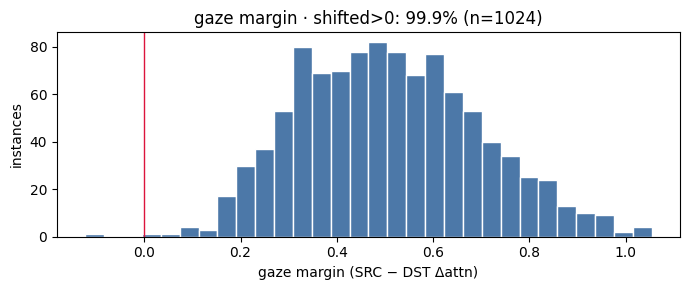

In [8]:
import matplotlib.pyplot as plt
m = df.gaze_margin.dropna().astype(float)
if len(m):
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.hist(m, bins=30, color="#4c78a8", edgecolor="white")
    ax.axvline(0, color="crimson", lw=1)
    ax.set_xlabel("gaze margin (SRC − DST Δattn)"); ax.set_ylabel("instances")
    ax.set_title(f"gaze margin · shifted>{0}: {(m > 0).mean():.1%} (n={len(m)})")
    plt.tight_layout(); plt.show()
else:
    print("no gaze margins")

## Gaze — corrected metric: does the patch make gaze prefer SRC over DST?

The saved `gaze.shifted` used the patched−clean **delta > 0** with no reference point, so it fired ~100% and wasn't discriminative. What we actually want: **after the patch**, does the pivot gaze more at the SRC left-out target span than at the DST left-out span — `gaze(SRC.leftout) > gaze(DST.leftout)` on the **absolute** patched attention. The credibility check is the **clean baseline**: before the patch, gaze should prefer the DST frontier (SRC>DST rare). Spans are located by string-matching each target description inside the saved `task_tokens` (no model needed).

In [9]:
# recompute gaze from the saved absolute attention (attn_patched / attn_clean over task_positions).
# spans: match each target description within the joined task_tokens -> token-index subset.
def _span_idx(task_tokens, desc):
    joined = "".join(task_tokens)
    ci = joined.find(desc)
    if ci < 0:                                   # tolerate whitespace/case drift
        ci = joined.lower().find(desc.lower().strip())
    if ci < 0:
        return []
    cj, idx, pos = ci + len(desc), [], 0
    for i, t in enumerate(task_tokens):
        if pos + len(t) > ci and pos < cj:
            idx.append(i)
        pos += len(t)
    return idx

recs, miss = [], 0
for d in config_dirs:
    for r in json.loads((d / "results.json").read_text()):
        raw = r["raw"]
        si, di = _span_idx(raw["task_tokens"], r["expected_next_desc"]), _span_idx(raw["task_tokens"], r["dst_next_desc"])
        if not si or not di:
            miss += 1
            recs.append((r["expected_next"], np.nan, np.nan, np.nan, np.nan)); continue
        ap, ac = np.asarray(raw["attn_patched"], float), np.asarray(raw["attn_clean"], float)
        recs.append((r["expected_next"], ap[si].mean(), ap[di].mean(), ac[si].mean(), ac[di].mean()))
gz = pd.DataFrame(recs, columns=["_chk", "src_pat", "dst_pat", "src_clean", "dst_clean"])
assert (gz["_chk"].values == df["expected_next"].values).all(), "row alignment mismatch"
for c in ["src_pat", "dst_pat", "src_clean", "dst_clean"]:
    df["gaze_" + c] = gz[c].values
df["gaze_abs"]     = df.gaze_src_pat > df.gaze_dst_pat          # patched: gaze(SRC) > gaze(DST)?
df["gaze_clean"]   = df.gaze_src_clean > df.gaze_dst_clean      # baseline: before the patch
df["gaze_abs_f"]   = df.gaze_abs.map({True: 1.0, False: 0.0})
df["gaze_abs_margin"] = df.gaze_src_pat - df.gaze_dst_pat

print(f"span-miss={miss}/{len(df)}")
print(f"clean baseline  gaze(SRC)>gaze(DST) : {df.gaze_clean.mean():.1%}   <- should be LOW (clean prefers DST frontier)")
print(f"PATCHED         gaze(SRC)>gaze(DST) : {df.gaze_abs.mean():.1%}   <- the patch flips gaze toward SRC")
print(f"(old delta>0 metric was            : {df.gaze_shifted_f.mean():.1%})")

for axis in ["datatype", "naming", "lang"]:
    g = df.groupby(axis).agg(n=("gaze_abs", "size"), clean=("gaze_clean", "mean"), patched=("gaze_abs", "mean"))
    print(f"=== by {axis} ===")
    display(g.style.format({"clean": "{:.1%}", "patched": "{:.1%}"}))

# gaze-shift is near-necessary but not sufficient: does it co-occur with causal success?
print("corrected gaze (patched SRC>DST) vs causal success:")
display(pd.crosstab(df.causal_triggered, df.gaze_abs, dropna=False))

span-miss=0/1024
clean baseline  gaze(SRC)>gaze(DST) : 1.2%   <- should be LOW (clean prefers DST frontier)
PATCHED         gaze(SRC)>gaze(DST) : 99.8%   <- the patch flips gaze toward SRC
(old delta>0 metric was            : 99.9%)
=== by datatype ===


,n,clean,patched
datatype,,,
int,256,2.3%,100.0%
list[int],256,0.4%,100.0%
list[str],256,1.6%,100.0%
str,256,0.4%,99.2%


=== by naming ===


,n,clean,patched
naming,,,
letters,508,0.4%,99.6%
natural,516,1.9%,100.0%


=== by lang ===


,n,clean,patched
lang,,,
python->cpp,512,0.6%,99.6%
python->python,512,1.8%,100.0%


corrected gaze (patched SRC>DST) vs causal success:


gaze_abs,False,True
causal_triggered,,
False,2,170
True,0,852


## Qualitative — inspect a few instances

Eyeball the patched generation + the three readouts against the SRC/DST targets.

In [10]:
def show_instance(row):
    print(f"[{row.config}]  expected(SRC)={row.expected_next!r} ({row.expected_next_desc})")
    print(f"                 dst_next   ={row.dst_next!r} ({row.dst_next_desc})")
    print(f"  causal={row.causal_label} triggered={row.causal_triggered} | "
          f"readout {row.ro_source}->{row.ro_dest}->{row.ro_patched} "
          f"(valid={row.readout_valid}, shifted={row.readout_shifted}) | gaze_shift={row.gaze_shifted}")
    print("  readout src :", row.ro_src_txt)
    print("  readout dst :", row.ro_dst_txt)
    print("  readout pat :", row.ro_pat_txt)
    print("  patched gen :\n    " + row.gen_patched.replace("\n", "\n    "))
    print("-" * 90)

# a few triggered and a few not (fall back to head() if oracle skipped)
trig = df[df.causal_triggered == True].head(2)
notrig = df[df.causal_triggered == False].head(2)
sample = pd.concat([trig, notrig]) if len(trig) + len(notrig) else df.head(3)
for _, row in sample.iterrows():
    show_instance(row)

[q__int__randnm__python-cpp]  expected(SRC)='sign' (the sign of the number)
                 dst_next   ='digit_count' (the number of digits)
  causal=src triggered=True | readout src->dst->src (valid=True, shifted=True) | gaze_shift=True
  readout src : I'm checking if the number is positive, negative, or zero to determine its sign.
  readout dst : I'm counting the number of characters in the string representation of the variable to determine its length.
  readout pat : I'm checking the sign of the variable to determine if it's positive, negative, or zero.
  patched gen :
     int sign = (n > 0) - (n < 0);
        return std::make_tuple(sign, count_set_bits, n == 0 ? 1 : floor(log10(abs(n))) + 1);
    }
    </code>
------------------------------------------------------------------------------------------
[q__int__randnm__python-cpp]  expected(SRC)='is_palindrome' (whether the number reads the same forwards and backwards)
                 dst_next   ='is_negative' (whether the number i

## Config-level summary (from each `meta.json`)

In [11]:
metas = [json.loads((d / "meta.json").read_text()) for d in config_dirs if (d / "meta.json").exists()]
mdf = pd.DataFrame(metas)
cols = ["datatype", "naming", "src_lang", "dst_lang", "n_instances",
        "causal_trigger_rate", "readout_valid_rate", "readout_shift_rate_valid", "gaze_shift_rate"]
display(mdf[[c for c in cols if c in mdf.columns]])

,datatype,naming,src_lang,dst_lang,n_instances,causal_trigger_rate,readout_valid_rate,readout_shift_rate_valid,gaze_shift_rate
0,int,random,python,cpp,128,0.750000,0.765625,0.928571,1.000000
1,int,random,python,python,128,0.789062,0.875000,0.937500,1.000000
2,list[int],random,python,cpp,128,0.929688,0.835938,0.906542,1.000000
3,list[int],random,python,python,128,0.820312,0.859375,0.945455,1.000000
4,list[str],random,python,cpp,128,0.835938,0.757812,0.969072,1.000000
5,list[str],random,python,python,128,0.929688,0.820312,0.990476,1.000000
6,str,random,python,cpp,128,0.812500,0.679688,0.931034,0.992188
7,str,random,python,python,128,0.789062,0.906250,0.948276,1.000000
